# Full-numerical density-driven phase-boundary catch-up

This notebook uses the completed full-numerical radial-continuation dataset at fixed $T(0^+)=5\,\mathrm{MeV}$. It compares two initial separations, $z_0=1\,\mathrm{km}$ and $z_0=100\,\mathrm{m}$, under two definitions of the spatial origin.

For either reference,

$$
\frac{n_B(0^-;z)}{n_0}
=
\frac{n_{B,\mathrm{ref}}(T)}{n_0}
+
\left(0.3\,\mathrm{km}^{-1}\right)z.
$$

The first reference is the fixed-$T(0^+)$, $\Delta h=0$ boundary where the present hydrodynamic velocity reaches zero. The second reference is the common-temperature PNM $\leftrightarrow$ udsQM coexistence curve shown as a purple dash-dot line. In the latter coordinate system the hydrodynamic front generally stops at a positive distance

$$
z_{\mathrm{stall}}=
\frac{n_{B,\Delta h=0}(T)/n_0-n_{B,\mathrm{eq}}(T)/n_0}
{0.3\,\mathrm{km}^{-1}}.
$$

The coexistence curve therefore defines a geometric origin only; it does not replace the stopping condition of the non-isothermal $T(0^+)=5\,\mathrm{MeV}$ velocity model. No velocity is extrapolated into the stable-neutron region.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from scipy.integrate import quad, solve_ivp
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq

ROOT = Path.cwd()
CONTOUR_DOMAIN_PATH = ROOT / "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-domain.npy"
FULL_NUMERICAL_PATH = ROOT / "new_paper_calculations/26-08-12/T0plus5-all-zero-upstream-v1-uNmax-radial-continuation-T0minus0-local-patched.npy"
EQUILIBRIUM_CURVE_PATH = ROOT / "local_analysis_results/26SU-11/phase-overlay-curves.npy"
OUTPUT_DIRECTORY = ROOT / "local_analysis_results/26SU-12"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

T_0PLUS_MEV = 5.0
TEMPERATURES_0MINUS_MEV = (0.0, 20.0, 40.0, 60.0)
INITIAL_SEPARATIONS_KM = (1.0, 0.1)
DENSITY_SLOPE_N0_PER_KM = 0.3
REFERENCE_DELTA_H_ZERO = "delta_h_zero"
REFERENCE_UDS_EQUILIBRIUM = "uds_equilibrium"
SCENARIO_SPECS = (
    {
        "reference_kind": REFERENCE_DELTA_H_ZERO,
        "z0_km": 1.0,
        "title": r"$z=0$: $\Delta h=0$, $z_0=1\,\mathrm{km}$",
        "output_stem": "paired-delta-h-zero-z0-1km",
    },
    {
        "reference_kind": REFERENCE_DELTA_H_ZERO,
        "z0_km": 0.1,
        "title": r"$z=0$: $\Delta h=0$, $z_0=100\,\mathrm{m}$",
        "output_stem": "paired-delta-h-zero-z0-100m",
    },
    {
        "reference_kind": REFERENCE_UDS_EQUILIBRIUM,
        "z0_km": 1.0,
        "title": r"$z=0$: PNM $\leftrightarrow$ udsQM, $z_0=1\,\mathrm{km}$",
        "output_stem": "paired-uds-equilibrium-z0-1km",
    },
    {
        "reference_kind": REFERENCE_UDS_EQUILIBRIUM,
        "z0_km": 0.1,
        "title": r"$z=0$: PNM $\leftrightarrow$ udsQM, $z_0=100\,\mathrm{m}$",
        "output_stem": "paired-uds-equilibrium-z0-100m",
    },
)
PRIMARY_TAIL_MAX_FRACTION = 0.10
SENSITIVITY_TAIL_MAX_FRACTIONS = (0.15, 0.20)
RESOLVED_SLICE_SAMPLE_COUNT = 500
EVOLUTION_OUTPUT_COUNT = 800
ODE_RTOL = 1.0e-9
ODE_ATOL_KM = 1.0e-11
TIME_CROSSCHECK_RTOL = 1.0e-3
NATIVE_COORDINATE_SNAP_ATOL = 1.0e-12
TIME_WINDOW_PADDING_FACTOR = 1.10
DEFAULT_TIME_WINDOW_S = 20.0

domain = np.load(CONTOUR_DOMAIN_PATH, allow_pickle=True).item()
full_numerical = np.load(FULL_NUMERICAL_PATH, allow_pickle=True).item()
equilibrium_payload = np.load(EQUILIBRIUM_CURVE_PATH, allow_pickle=True).item()

temperature_0plus_axis = np.asarray(domain["T_0plus_values_MeV"], dtype=float)
if temperature_0plus_axis.shape != (1,) or not np.isclose(temperature_0plus_axis[0], T_0PLUS_MEV):
    raise RuntimeError(f"Expected only T(0+)={T_0PLUS_MEV:g} MeV, found {temperature_0plus_axis}")
if not np.array_equal(
    np.asarray(full_numerical["T_0plus_values_MeV"], dtype=float),
    temperature_0plus_axis,
):
    raise RuntimeError("Domain and full-numerical payload use different T(0+) axes")
if not bool(full_numerical.get("run_complete", False)):
    raise RuntimeError("The selected full-numerical radial-continuation payload is incomplete")

domain_B14_MeV = float(domain["calibration"]["B14_MeV"])
equilibrium_B14_MeV = float(equilibrium_payload["B14_MeV"])
if not np.isclose(domain_B14_MeV, equilibrium_B14_MeV, rtol=1.0e-12, atol=0.0):
    raise RuntimeError("The PNM-udsQM curve and full-numerical domain use different bag constants")

uds_equilibrium_temperature_MeV = np.asarray(
    equilibrium_payload["uds_temperature_MeV"], dtype=float
)
uds_equilibrium_density_over_n0 = np.asarray(
    equilibrium_payload["uds_nB_0minus_over_n0"], dtype=float
)
if (
    uds_equilibrium_temperature_MeV.ndim != 1
    or uds_equilibrium_density_over_n0.shape != uds_equilibrium_temperature_MeV.shape
    or np.any(~np.isfinite(uds_equilibrium_temperature_MeV))
    or np.any(~np.isfinite(uds_equilibrium_density_over_n0))
    or np.any(np.diff(uds_equilibrium_temperature_MeV) <= 0.0)
):
    raise RuntimeError("Invalid cached PNM-udsQM coexistence curve")
if min(TEMPERATURES_0MINUS_MEV) < uds_equilibrium_temperature_MeV[0] or max(TEMPERATURES_0MINUS_MEV) > uds_equilibrium_temperature_MeV[-1]:
    raise RuntimeError("Requested temperatures lie outside the PNM-udsQM coexistence cache")
uds_equilibrium_density_interpolator = PchipInterpolator(
    uds_equilibrium_temperature_MeV,
    uds_equilibrium_density_over_n0,
    extrapolate=False,
)

theta_axis = np.linspace(0.0, 0.5 * np.pi, 30)
radial_fraction_axis = np.asarray(full_numerical["contour_radial_fraction_axis"], dtype=float)
density_grid = np.asarray(full_numerical["nB_0minus_over_n0_grid"], dtype=float)[:, :, 0]
temperature_0minus_grid = np.asarray(full_numerical["T_0minus_MeV_grid"], dtype=float)[:, :, 0]
velocity_grid_m_s = np.asarray(
    full_numerical["numerical_outward_u_0minus_m_s_grid"], dtype=float
)[:, :, 0]
success_grid = np.asarray(
    full_numerical["numerical_outward_success_grid"], dtype=bool
)[:, :, 0]

EXPECTED_GRID_SHAPE = (30, 20)
EXPECTED_ACCEPTED_CELLS = 516
if density_grid.shape != EXPECTED_GRID_SHAPE:
    raise RuntimeError(f"Expected numerical grid {EXPECTED_GRID_SHAPE}, found {density_grid.shape}")
if int(np.count_nonzero(success_grid)) != EXPECTED_ACCEPTED_CELLS:
    raise RuntimeError(
        f"Expected {EXPECTED_ACCEPTED_CELLS}/600 successful cells, "
        f"found {int(np.count_nonzero(success_grid))}/600"
    )

transform = domain["transform"]
DENSITY_ORIGIN_OVER_N0 = float(transform["density_origin_over_n0"])
DENSITY_SCALE_OVER_N0 = float(transform["density_scale_over_n0"])
TEMPERATURE_SCALE_MEV = float(transform["temperature_scale_MeV"])
boundary_diagnostics = domain["boundary_diagnostics"]["semi_analytic"]
inner_boundary_records = boundary_diagnostics["gap_curve_records_by_T0plus"][T_0PLUS_MEV]
outer_boundary_records = boundary_diagnostics["A_curve_records"]

print(f"Loaded fixed T(0+)={T_0PLUS_MEV:g} MeV domain")
print(f"Full-numerical accepted cells: {int(np.count_nonzero(success_grid))}/{success_grid.size}")
print(f"Loaded {uds_equilibrium_temperature_MeV.size} PNM-udsQM coexistence points")

Loaded fixed T(0+)=5 MeV domain
Full-numerical accepted cells: 516/600
Loaded 61 PNM-udsQM coexistence points


## Topology-preserving velocity interpolation and generalized distance origin

Interpolation remains in the native ray coordinates $(\theta,f)$. A triangle is usable only if all three vertices are successful, so numerical holes and excluded regions are never bridged.

The full-numerical velocity depends on the active distance from the $\Delta h=0$ boundary,

$$
z_{\mathrm{hydro}}=z-z_{\mathrm{stall}}.
$$

For $z_{\mathrm{hydro}}>0$, resolved numerical values are interpolated with PCHIP and the unsampled $f<0.02$ interval uses the fitted positive power law. A case can therefore use the resolved grid plus the tail, the tail alone, or return `no_advancing_solution` when it begins at $z_{\mathrm{hydro}}\leq0$.

In [2]:
def _ordered_boundary_arrays(records):
    ordered = sorted(records, key=lambda row: float(row["theta_rad"]))
    theta = np.asarray([row["theta_rad"] for row in ordered], dtype=float)
    rho = np.asarray([row["rho"] for row in ordered], dtype=float)
    return theta, rho


INNER_BOUNDARY_THETA, INNER_BOUNDARY_RHO = _ordered_boundary_arrays(inner_boundary_records)
OUTER_BOUNDARY_THETA, OUTER_BOUNDARY_RHO = _ordered_boundary_arrays(outer_boundary_records)


def boundary_rho(theta_rad, boundary_kind):
    theta_rad = np.asarray(theta_rad, dtype=float)
    if boundary_kind == "inner":
        return np.interp(theta_rad, INNER_BOUNDARY_THETA, INNER_BOUNDARY_RHO)
    if boundary_kind == "outer":
        return np.interp(theta_rad, OUTER_BOUNDARY_THETA, OUTER_BOUNDARY_RHO)
    raise ValueError(f"Unknown boundary kind: {boundary_kind}")


def physical_state_from_native(theta_rad, radial_fraction):
    theta_rad = np.asarray(theta_rad, dtype=float)
    radial_fraction = np.asarray(radial_fraction, dtype=float)
    rho_inner = boundary_rho(theta_rad, "inner")
    rho_outer = boundary_rho(theta_rad, "outer")
    rho = rho_inner + radial_fraction * (rho_outer - rho_inner)
    density_over_n0 = (
        DENSITY_ORIGIN_OVER_N0
        + DENSITY_SCALE_OVER_N0 * rho * np.cos(theta_rad)
    )
    temperature_0minus_MeV = TEMPERATURE_SCALE_MEV * rho * np.sin(theta_rad)
    return density_over_n0, temperature_0minus_MeV


def native_state_from_physical(density_over_n0, temperature_0minus_MeV):
    coordinate_x = (
        np.asarray(density_over_n0, dtype=float) - DENSITY_ORIGIN_OVER_N0
    ) / DENSITY_SCALE_OVER_N0
    coordinate_y = np.asarray(temperature_0minus_MeV, dtype=float) / TEMPERATURE_SCALE_MEV
    theta_rad = np.arctan2(coordinate_y, coordinate_x)
    rho = np.hypot(coordinate_x, coordinate_y)
    rho_inner = boundary_rho(theta_rad, "inner")
    rho_outer = boundary_rho(theta_rad, "outer")
    radial_fraction = (rho - rho_inner) / (rho_outer - rho_inner)
    return theta_rad, radial_fraction


def state_at_temperature_and_fraction(temperature_0minus_MeV, radial_fraction):
    temperature_0minus_MeV = float(temperature_0minus_MeV)
    radial_fraction = float(radial_fraction)
    if temperature_0minus_MeV < 0.0:
        raise ValueError("T(0-) must be non-negative")
    if np.isclose(temperature_0minus_MeV, 0.0):
        theta_rad = 0.0
    else:
        def temperature_residual(theta_trial):
            _, temperature_trial = physical_state_from_native(theta_trial, radial_fraction)
            return float(temperature_trial - temperature_0minus_MeV)

        endpoint_residual = temperature_residual(0.5 * np.pi)
        if endpoint_residual < 0.0:
            raise ValueError(
                f"T(0-)={temperature_0minus_MeV:g} MeV lies above the selected boundary"
            )
        theta_rad = brentq(temperature_residual, 0.0, 0.5 * np.pi, xtol=1.0e-13)
    density_over_n0, temperature_check = physical_state_from_native(theta_rad, radial_fraction)
    return {
        "theta_rad": float(theta_rad),
        "radial_fraction": radial_fraction,
        "density_over_n0": float(density_over_n0),
        "temperature_0minus_MeV": float(temperature_check),
    }


def build_masked_velocity_triangulation(
    theta_values,
    radial_fraction_values,
    velocity_values_m_s,
    successful_values,
):
    theta_values = np.asarray(theta_values, dtype=float)
    radial_fraction_values = np.asarray(radial_fraction_values, dtype=float)
    velocity_values_m_s = np.asarray(velocity_values_m_s, dtype=float)
    successful_values = np.asarray(successful_values, dtype=bool)
    expected_shape = (theta_values.size, radial_fraction_values.size)
    if velocity_values_m_s.shape != expected_shape or successful_values.shape != expected_shape:
        raise ValueError("Velocity and success grids do not match native axes")

    theta_mesh, fraction_mesh = np.meshgrid(
        theta_values, radial_fraction_values, indexing="ij"
    )
    triangles = []
    triangle_masks = []
    fraction_count = radial_fraction_values.size
    for theta_index in range(theta_values.size - 1):
        for fraction_index in range(radial_fraction_values.size - 1):
            lower_left = theta_index * fraction_count + fraction_index
            lower_right = lower_left + 1
            upper_left = lower_left + fraction_count
            upper_right = upper_left + 1
            for triangle in (
                (lower_left, lower_right, upper_right),
                (lower_left, upper_right, upper_left),
            ):
                triangles.append(triangle)
                triangle_masks.append(
                    not all(successful_values.ravel()[vertex] for vertex in triangle)
                )

    triangulation = mtri.Triangulation(
        theta_mesh.ravel(),
        fraction_mesh.ravel(),
        triangles=np.asarray(triangles, dtype=int),
        mask=np.asarray(triangle_masks, dtype=bool),
    )
    velocity_for_interpolation = np.where(
        successful_values & np.isfinite(velocity_values_m_s),
        velocity_values_m_s,
        0.0,
    )
    interpolator = mtri.LinearTriInterpolator(
        triangulation,
        velocity_for_interpolation.ravel(),
    )
    return triangulation, interpolator


velocity_triangulation, native_velocity_interpolator = build_masked_velocity_triangulation(
    theta_axis,
    radial_fraction_axis,
    velocity_grid_m_s,
    success_grid,
)


def interpolate_numerical_velocity(density_over_n0, temperature_0minus_MeV):
    theta_rad, radial_fraction = native_state_from_physical(
        density_over_n0, temperature_0minus_MeV
    )
    theta_rad = float(theta_rad)
    radial_fraction = float(radial_fraction)
    if np.isclose(theta_rad, theta_axis[0], rtol=0.0, atol=NATIVE_COORDINATE_SNAP_ATOL):
        theta_rad = float(theta_axis[0])
    elif np.isclose(theta_rad, theta_axis[-1], rtol=0.0, atol=NATIVE_COORDINATE_SNAP_ATOL):
        theta_rad = float(theta_axis[-1])
    if np.isclose(
        radial_fraction,
        radial_fraction_axis[0],
        rtol=0.0,
        atol=NATIVE_COORDINATE_SNAP_ATOL,
    ):
        radial_fraction = float(radial_fraction_axis[0])
    elif np.isclose(
        radial_fraction,
        radial_fraction_axis[-1],
        rtol=0.0,
        atol=NATIVE_COORDINATE_SNAP_ATOL,
    ):
        radial_fraction = float(radial_fraction_axis[-1])
    interpolated = native_velocity_interpolator(theta_rad, radial_fraction)
    if np.ma.is_masked(interpolated):
        return np.nan
    value = float(np.asarray(interpolated))
    return value if np.isfinite(value) and value > 0.0 else np.nan


def fit_power_law_tail(temperature_0minus_MeV, maximum_fraction):
    selected_fractions = radial_fraction_axis[
        radial_fraction_axis <= float(maximum_fraction) + 1.0e-12
    ]
    if selected_fractions.size < 3:
        raise ValueError("Power-law tail fit requires at least three radial layers")

    boundary_state = state_at_temperature_and_fraction(temperature_0minus_MeV, 0.0)
    density_zero_over_n0 = boundary_state["density_over_n0"]
    z_values_km = []
    velocity_values_m_s = []
    density_values_over_n0 = []
    for radial_fraction in selected_fractions:
        state = state_at_temperature_and_fraction(
            temperature_0minus_MeV, radial_fraction
        )
        velocity_m_s = interpolate_numerical_velocity(
            state["density_over_n0"], temperature_0minus_MeV
        )
        if not np.isfinite(velocity_m_s):
            raise RuntimeError(
                f"Missing numerical velocity at T(0-)={temperature_0minus_MeV:g} MeV, "
                f"f={radial_fraction:g}"
            )
        z_km = (
            state["density_over_n0"] - density_zero_over_n0
        ) / DENSITY_SLOPE_N0_PER_KM
        if z_km <= 0.0:
            raise RuntimeError("Near-boundary numerical layer does not have positive z")
        z_values_km.append(z_km)
        velocity_values_m_s.append(velocity_m_s)
        density_values_over_n0.append(state["density_over_n0"])

    z_values_km = np.asarray(z_values_km, dtype=float)
    velocity_values_m_s = np.asarray(velocity_values_m_s, dtype=float)
    exponent, fitted_log_amplitude = np.polyfit(
        np.log(z_values_km), np.log(velocity_values_m_s), 1
    )
    if exponent <= 0.0:
        raise RuntimeError(
            f"Non-positive near-boundary exponent p={exponent:.6g} at "
            f"T(0-)={temperature_0minus_MeV:g} MeV"
        )

    return {
        "maximum_fraction": float(maximum_fraction),
        "fractions": np.asarray(selected_fractions, dtype=float),
        "z_values_km": z_values_km,
        "density_values_over_n0": np.asarray(density_values_over_n0, dtype=float),
        "velocity_values_m_s": velocity_values_m_s,
        "exponent": float(exponent),
        "unanchored_amplitude": float(np.exp(fitted_log_amplitude)),
        "z_join_km": float(z_values_km[0]),
        "velocity_join_m_s": float(velocity_values_m_s[0]),
    }



def equilibrium_density_over_n0(temperature_0minus_MeV):
    value = float(uds_equilibrium_density_interpolator(float(temperature_0minus_MeV)))
    if not np.isfinite(value):
        raise RuntimeError(
            f"PNM-udsQM equilibrium density unavailable at T(0-)={temperature_0minus_MeV:g} MeV"
        )
    return value


def reference_density_over_n0(reference_kind, temperature_0minus_MeV):
    delta_h_zero_density = state_at_temperature_and_fraction(
        temperature_0minus_MeV, 0.0
    )["density_over_n0"]
    if reference_kind == REFERENCE_DELTA_H_ZERO:
        return float(delta_h_zero_density)
    if reference_kind == REFERENCE_UDS_EQUILIBRIUM:
        return equilibrium_density_over_n0(temperature_0minus_MeV)
    raise ValueError(f"Unknown distance reference: {reference_kind}")


def power_law_travel_time_s(initial_active_distance_km, tail_fit):
    initial_active_distance_km = float(initial_active_distance_km)
    exponent = float(tail_fit["exponent"])
    if initial_active_distance_km <= 0.0:
        return 0.0
    if exponent >= 1.0:
        return np.inf
    z_join_km = float(tail_fit["z_join_km"])
    velocity_join_m_s = float(tail_fit["velocity_join_m_s"])
    return float(
        1000.0
        * z_join_km
        / (velocity_join_m_s * (1.0 - exponent))
        * (initial_active_distance_km / z_join_km) ** (1.0 - exponent)
    )


def power_law_distance_km(initial_active_distance_km, elapsed_time_s, tail_fit):
    initial_active_distance_km = float(initial_active_distance_km)
    elapsed_time_s = np.asarray(elapsed_time_s, dtype=float)
    duration_s = power_law_travel_time_s(initial_active_distance_km, tail_fit)
    exponent = float(tail_fit["exponent"])
    if not np.isfinite(duration_s):
        raise RuntimeError("The fitted tail does not reach zero in finite time")
    remaining_fraction = np.maximum(0.0, 1.0 - elapsed_time_s / duration_s)
    return initial_active_distance_km * remaining_fraction ** (1.0 / (1.0 - exponent))


def solve_active_distance_evolution(temperature_0minus_MeV, initial_active_distance_km):
    temperature_0minus_MeV = float(temperature_0minus_MeV)
    initial_active_distance_km = float(initial_active_distance_km)
    primary_tail = fit_power_law_tail(
        temperature_0minus_MeV, PRIMARY_TAIL_MAX_FRACTION
    )
    sensitivity_tails = tuple(
        fit_power_law_tail(temperature_0minus_MeV, maximum_fraction)
        for maximum_fraction in SENSITIVITY_TAIL_MAX_FRACTIONS
    )
    if not 0.0 < float(primary_tail["exponent"]) < 1.0:
        raise RuntimeError(
            f"Primary tail at T(0-)={temperature_0minus_MeV:g} MeV does not have 0<p<1"
        )

    if initial_active_distance_km <= 0.0:
        return {
            "status": "no_advancing_solution",
            "initial_active_distance_km": initial_active_distance_km,
            "primary_tail": primary_tail,
            "sensitivity_tails": sensitivity_tails,
            "resolved_time_ode_s": 0.0,
            "resolved_time_quadrature_s": 0.0,
            "tail_time_s": np.nan,
            "stop_time_s": np.nan,
            "quadrature_stop_time_s": np.nan,
            "sensitivity_stop_times_s": np.full(len(sensitivity_tails), np.nan),
            "active_distance_at_time": None,
        }

    z_join_km = float(primary_tail["z_join_km"])
    velocity_join_m_s = float(primary_tail["velocity_join_m_s"])
    if initial_active_distance_km <= z_join_km:
        tail_time_s = power_law_travel_time_s(
            initial_active_distance_km, primary_tail
        )
        quadrature_stop_time_s = float(
            quad(
                lambda distance_km: 1000.0
                / (
                    velocity_join_m_s
                    * (distance_km / z_join_km) ** float(primary_tail["exponent"])
                ),
                0.0,
                initial_active_distance_km,
                epsabs=1.0e-9,
                epsrel=1.0e-10,
                limit=300,
            )[0]
        )

        def active_distance_at_time(time_s, tail_fit=primary_tail):
            return power_law_distance_km(
                initial_active_distance_km, time_s, tail_fit
            )

        return {
            "status": "tail_only",
            "initial_active_distance_km": initial_active_distance_km,
            "primary_tail": primary_tail,
            "sensitivity_tails": sensitivity_tails,
            "resolved_time_ode_s": 0.0,
            "resolved_time_quadrature_s": 0.0,
            "tail_time_s": tail_time_s,
            "stop_time_s": tail_time_s,
            "quadrature_stop_time_s": quadrature_stop_time_s,
            "sensitivity_stop_times_s": np.asarray(
                [
                    power_law_travel_time_s(initial_active_distance_km, tail_fit)
                    for tail_fit in sensitivity_tails
                ],
                dtype=float,
            ),
            "active_distance_at_time": active_distance_at_time,
        }

    resolved_distance_km = np.linspace(
        z_join_km, initial_active_distance_km, RESOLVED_SLICE_SAMPLE_COUNT
    )
    delta_h_zero_density_over_n0 = state_at_temperature_and_fraction(
        temperature_0minus_MeV, 0.0
    )["density_over_n0"]
    resolved_density_over_n0 = (
        delta_h_zero_density_over_n0
        + DENSITY_SLOPE_N0_PER_KM * resolved_distance_km
    )
    resolved_velocity_m_s = np.asarray(
        [
            interpolate_numerical_velocity(density_value, temperature_0minus_MeV)
            for density_value in resolved_density_over_n0
        ],
        dtype=float,
    )
    if not np.all(np.isfinite(resolved_velocity_m_s)):
        first_invalid = int(np.flatnonzero(~np.isfinite(resolved_velocity_m_s))[0])
        raise RuntimeError(
            f"The requested path crosses an unavailable numerical triangle at "
            f"z_hydro={resolved_distance_km[first_invalid]:.6g} km"
        )
    if np.any(resolved_velocity_m_s <= 0.0):
        raise RuntimeError("Resolved numerical slice contains a non-positive velocity")

    resolved_interpolator = PchipInterpolator(
        resolved_distance_km, resolved_velocity_m_s, extrapolate=False
    )

    def resolved_velocity(distance_km):
        value = float(resolved_interpolator(float(distance_km)))
        if not np.isfinite(value) or value <= 0.0:
            raise RuntimeError(
                f"Resolved velocity unavailable at z_hydro={distance_km:.6g} km"
            )
        return value

    resolved_time_quadrature_s = float(
        quad(
            lambda distance_km: 1000.0 / resolved_velocity(distance_km),
            z_join_km,
            initial_active_distance_km,
            epsabs=1.0e-9,
            epsrel=1.0e-10,
            limit=300,
        )[0]
    )

    def resolved_rhs(_time_s, active_distance_km):
        # RK trial stages may cross the terminal event before it is located.
        # Clamp only those internal stages to the resolved/tail join; the
        # accepted evolution switches to the fitted tail at the event.
        distance_for_rhs_km = max(float(active_distance_km[0]), z_join_km)
        return np.array([-resolved_velocity(distance_for_rhs_km) / 1000.0])

    def reach_tail_join(_time_s, active_distance_km):
        return float(active_distance_km[0] - z_join_km)

    reach_tail_join.terminal = True
    reach_tail_join.direction = -1
    integration_horizon_s = max(1.0, 1.5 * resolved_time_quadrature_s + 1.0)
    resolved_solution = solve_ivp(
        resolved_rhs,
        (0.0, integration_horizon_s),
        np.array([initial_active_distance_km], dtype=float),
        events=reach_tail_join,
        dense_output=True,
        rtol=ODE_RTOL,
        atol=ODE_ATOL_KM,
        max_step=max(1.0e-4, integration_horizon_s / 500.0),
    )
    if not resolved_solution.success or resolved_solution.t_events[0].size != 1:
        raise RuntimeError("Resolved active-distance integration did not reach the tail join")
    resolved_time_ode_s = float(resolved_solution.t_events[0][0])
    tail_time_s = power_law_travel_time_s(z_join_km, primary_tail)
    stop_time_s = resolved_time_ode_s + tail_time_s
    quadrature_stop_time_s = resolved_time_quadrature_s + tail_time_s

    def active_distance_at_time(time_s, tail_fit=primary_tail):
        time_s = np.asarray(time_s, dtype=float)
        output = np.empty_like(time_s)
        resolved_mask = time_s <= resolved_time_ode_s
        if np.any(resolved_mask):
            output[resolved_mask] = np.asarray(
                resolved_solution.sol(time_s[resolved_mask])[0], dtype=float
            )
        if np.any(~resolved_mask):
            output[~resolved_mask] = power_law_distance_km(
                z_join_km,
                time_s[~resolved_mask] - resolved_time_ode_s,
                tail_fit,
            )
        return np.maximum(output, 0.0)

    return {
        "status": "resolved_and_tail",
        "initial_active_distance_km": initial_active_distance_km,
        "primary_tail": primary_tail,
        "sensitivity_tails": sensitivity_tails,
        "resolved_time_ode_s": resolved_time_ode_s,
        "resolved_time_quadrature_s": resolved_time_quadrature_s,
        "tail_time_s": tail_time_s,
        "stop_time_s": stop_time_s,
        "quadrature_stop_time_s": quadrature_stop_time_s,
        "sensitivity_stop_times_s": np.asarray(
            [
                resolved_time_ode_s
                + power_law_travel_time_s(z_join_km, tail_fit)
                for tail_fit in sensitivity_tails
            ],
            dtype=float,
        ),
        "active_distance_at_time": active_distance_at_time,
    }


def nice_time_window(maximum_time_s):
    target_maximum_s = max(
        DEFAULT_TIME_WINDOW_S, float(maximum_time_s) * TIME_WINDOW_PADDING_FACTOR
    )
    raw_step_s = target_maximum_s / 6.0
    power = 10.0 ** np.floor(np.log10(raw_step_s))
    normalized = raw_step_s / power
    if normalized <= 1.0:
        step_s = 1.0 * power
    elif normalized <= 2.0:
        step_s = 2.0 * power
    elif normalized <= 5.0:
        step_s = 5.0 * power
    else:
        step_s = 10.0 * power
    maximum_s = float(np.ceil(target_maximum_s / step_s) * step_s)
    return maximum_s, float(step_s)


def solve_reference_scenario(scenario_spec):
    reference_kind = str(scenario_spec["reference_kind"])
    z0_km = float(scenario_spec["z0_km"])
    results = []
    for temperature_0minus_MeV in TEMPERATURES_0MINUS_MEV:
        temperature_0minus_MeV = float(temperature_0minus_MeV)
        delta_h_zero_density_over_n0 = state_at_temperature_and_fraction(
            temperature_0minus_MeV, 0.0
        )["density_over_n0"]
        reference_density_value_over_n0 = reference_density_over_n0(
            reference_kind, temperature_0minus_MeV
        )
        initial_density_over_n0 = (
            reference_density_value_over_n0
            + DENSITY_SLOPE_N0_PER_KM * z0_km
        )
        z_stall_km = (
            delta_h_zero_density_over_n0 - reference_density_value_over_n0
        ) / DENSITY_SLOPE_N0_PER_KM
        if reference_kind == REFERENCE_DELTA_H_ZERO:
            z_stall_km = 0.0
        initial_active_distance_km = z0_km - z_stall_km
        active_result = solve_active_distance_evolution(
            temperature_0minus_MeV, initial_active_distance_km
        )

        if active_result["status"] == "no_advancing_solution":
            def distance_at_time(time_s, fixed_distance_km=z0_km):
                return np.full_like(
                    np.asarray(time_s, dtype=float), fixed_distance_km, dtype=float
                )
            stop_distance_km = z0_km
        else:
            active_distance_at_time = active_result["active_distance_at_time"]
            def distance_at_time(
                time_s,
                active_function=active_distance_at_time,
                fixed_stall_distance_km=z_stall_km,
            ):
                return fixed_stall_distance_km + active_function(time_s)
            stop_distance_km = z_stall_km

        results.append(
            {
                "reference_kind": reference_kind,
                "z0_km": z0_km,
                "temperature_0minus_MeV": temperature_0minus_MeV,
                "reference_density_over_n0": reference_density_value_over_n0,
                "initial_density_over_n0": initial_density_over_n0,
                "delta_h_zero_density_over_n0": delta_h_zero_density_over_n0,
                "z_stall_km": z_stall_km,
                "stop_distance_km": stop_distance_km,
                "distance_at_time": distance_at_time,
                **active_result,
            }
        )

    finite_stop_times_s = np.asarray(
        [result["stop_time_s"] for result in results if np.isfinite(result["stop_time_s"])],
        dtype=float,
    )
    largest_stop_time_s = (
        float(np.max(finite_stop_times_s))
        if finite_stop_times_s.size
        else DEFAULT_TIME_WINDOW_S
    )
    time_window_s, time_tick_step_s = nice_time_window(largest_stop_time_s)
    return {
        **dict(scenario_spec),
        "results": tuple(results),
        "time_window_s": time_window_s,
        "time_tick_step_s": time_tick_step_s,
    }


## Compute and validate all four scenarios

The table contains four temperatures for each of the four reference/separation combinations. `resolved_and_tail` and `tail_only` are moving solutions. `no_advancing_solution` means the selected initial point is already on the stable-neutron side of the $\Delta h=0$ boundary, so the plotted distance remains fixed without extrapolating the velocity model.

In [3]:
SCENARIO_RESULTS = tuple(
    solve_reference_scenario(scenario_spec) for scenario_spec in SCENARIO_SPECS
)
evolution_results = tuple(
    result for scenario in SCENARIO_RESULTS for result in scenario["results"]
)

summary_rows = []
for result in evolution_results:
    summary_rows.append(
        {
            "reference": result["reference_kind"],
            "z0 [km]": result["z0_km"],
            "T(0-) [MeV]": result["temperature_0minus_MeV"],
            "reference nB(0-)/n0": result["reference_density_over_n0"],
            "initial nB(0-)/n0": result["initial_density_over_n0"],
            "Delta-h-zero nB(0-)/n0": result["delta_h_zero_density_over_n0"],
            "z_stall [km]": result["z_stall_km"],
            "status": result["status"],
            "tail p": result["primary_tail"]["exponent"],
            "stop time [s]": result["stop_time_s"],
        }
    )

summary_table = pd.DataFrame(summary_rows)
if len(summary_table) != 16:
    raise RuntimeError(f"Expected 16 scenario rows, found {len(summary_table)}")
display(summary_table.style.format(precision=6))
print(summary_table.to_string(index=False, float_format=lambda value: f"{value:.6g}"))

# The native interpolator must reproduce every vertex belonging to an unmasked triangle.
usable_triangles = velocity_triangulation.triangles[~velocity_triangulation.mask]
usable_vertices = np.unique(usable_triangles.ravel())
theta_mesh, fraction_mesh = np.meshgrid(theta_axis, radial_fraction_axis, indexing="ij")
interpolated_vertices = native_velocity_interpolator(
    theta_mesh.ravel()[usable_vertices], fraction_mesh.ravel()[usable_vertices]
)
expected_vertices = velocity_grid_m_s.ravel()[usable_vertices]
if not np.allclose(
    np.asarray(interpolated_vertices, dtype=float),
    expected_vertices,
    rtol=1.0e-11,
    atol=1.0e-8,
):
    raise RuntimeError("Masked triangulation does not reproduce successful grid vertices")

masked_triangle_indices = np.flatnonzero(velocity_triangulation.mask)
if masked_triangle_indices.size == 0:
    raise RuntimeError("Expected at least one masked numerical triangle")
masked_triangle = velocity_triangulation.triangles[masked_triangle_indices[0]]
masked_centroid_value = native_velocity_interpolator(
    float(np.mean(velocity_triangulation.x[masked_triangle])),
    float(np.mean(velocity_triangulation.y[masked_triangle])),
)
if not np.ma.is_masked(masked_centroid_value):
    raise RuntimeError("Interpolation bridged across a masked numerical triangle")

for scenario in SCENARIO_RESULTS:
    reference_kind = scenario["reference_kind"]
    z0_km = float(scenario["z0_km"])
    for result in scenario["results"]:
        expected_initial_density = (
            result["reference_density_over_n0"]
            + DENSITY_SLOPE_N0_PER_KM * z0_km
        )
        if not np.isclose(
            result["initial_density_over_n0"], expected_initial_density,
            rtol=0.0, atol=1.0e-12,
        ):
            raise RuntimeError("Initial density does not satisfy the selected reference and slope")
        if not 0.0 < result["primary_tail"]["exponent"] < 1.0:
            raise RuntimeError("A primary tail does not produce finite-time stopping")

        check_time_s = np.linspace(0.0, scenario["time_window_s"], EVOLUTION_OUTPUT_COUNT)
        check_distance_km = result["distance_at_time"](check_time_s)
        if not np.isclose(check_distance_km[0], z0_km, rtol=0.0, atol=1.0e-10):
            raise RuntimeError("A curve does not start at the requested z0")
        if np.any(np.diff(check_distance_km) > 1.0e-10):
            raise RuntimeError("A distance curve moves away from its stopping point")

        if result["status"] == "no_advancing_solution":
            if not np.allclose(check_distance_km, z0_km, rtol=0.0, atol=1.0e-12):
                raise RuntimeError("A no-advancing-solution case is not flat")
            if np.isfinite(result["stop_time_s"]):
                raise RuntimeError("A no-advancing-solution case has a finite stop time")
        else:
            relative_time_difference = abs(
                result["stop_time_s"] - result["quadrature_stop_time_s"]
            ) / result["quadrature_stop_time_s"]
            if relative_time_difference > TIME_CROSSCHECK_RTOL:
                raise RuntimeError(
                    f"ODE/analytic/quadrature mismatch {relative_time_difference:.3e}"
                )
            final_distance_km = float(
                result["distance_at_time"](np.asarray([scenario["time_window_s"]]))[0]
            )
            if not np.isclose(
                final_distance_km, result["z_stall_km"], rtol=0.0, atol=1.0e-8
            ):
                raise RuntimeError("A moving curve does not remain at its stopping distance")

        if reference_kind == REFERENCE_DELTA_H_ZERO:
            if result["status"] == "no_advancing_solution":
                raise RuntimeError("A Delta-h-zero referenced case unexpectedly cannot advance")
            if not np.isclose(result["z_stall_km"], 0.0, atol=1.0e-12):
                raise RuntimeError("A Delta-h-zero referenced case does not stop at z=0")

equilibrium_one_km = next(
    scenario for scenario in SCENARIO_RESULTS
    if scenario["reference_kind"] == REFERENCE_UDS_EQUILIBRIUM
    and np.isclose(scenario["z0_km"], 1.0)
)
if any(result["status"] == "no_advancing_solution" for result in equilibrium_one_km["results"]):
    raise RuntimeError("Every one-km equilibrium-referenced case should initially advance")
if any(result["z_stall_km"] <= 0.0 for result in equilibrium_one_km["results"]):
    raise RuntimeError("Every equilibrium-referenced case should stop at positive z")

equilibrium_100m = next(
    scenario for scenario in SCENARIO_RESULTS
    if scenario["reference_kind"] == REFERENCE_UDS_EQUILIBRIUM
    and np.isclose(scenario["z0_km"], 0.1)
)
expected_100m_status = {
    0.0: "tail_only",
    20.0: "no_advancing_solution",
    40.0: "no_advancing_solution",
    60.0: "no_advancing_solution",
}
for result in equilibrium_100m["results"]:
    expected_status = expected_100m_status[result["temperature_0minus_MeV"]]
    if result["status"] != expected_status:
        raise RuntimeError(
            f"Unexpected 100-m equilibrium status at T(0-)={result['temperature_0minus_MeV']:g} MeV"
        )

print("ALL VALIDATION CHECKS PASSED")

,reference,z0 [km],T(0-) [MeV],reference nB(0-)/n0,initial nB(0-)/n0,Delta-h-zero nB(0-)/n0,z_stall [km],status,tail p,stop time [s]
0,delta_h_zero,1.000000,0.000000,3.013360,3.313360,3.013360,0.000000,resolved_and_tail,0.731753,38.081111
1,delta_h_zero,1.000000,20.000000,2.910184,3.210184,2.910184,0.000000,resolved_and_tail,0.723883,38.193434
2,delta_h_zero,1.000000,40.000000,2.542063,2.842063,2.542063,0.000000,resolved_and_tail,0.724989,43.193127
3,delta_h_zero,1.000000,60.000000,1.412986,1.712986,1.412986,0.000000,resolved_and_tail,0.811393,107.191096
4,delta_h_zero,0.100000,0.000000,3.013360,3.043360,3.013360,0.000000,tail_only,0.731753,20.403340
5,delta_h_zero,0.100000,20.000000,2.910184,2.940184,2.910184,0.000000,tail_only,0.723883,20.079064
6,delta_h_zero,0.100000,40.000000,2.542063,2.572063,2.542063,0.000000,tail_only,0.724989,22.743063
7,delta_h_zero,0.100000,60.000000,1.412986,1.442986,1.412986,0.000000,tail_only,0.811393,69.175871
8,uds_equilibrium,1.000000,0.000000,3.000000,3.300000,3.013360,0.044535,resolved_and_tail,0.731753,37.637152
9,uds_equilibrium,1.000000,20.000000,2.833385,3.133385,2.910184,0.255996,resolved_and_tail,0.723883,35.269724


      reference  z0 [km]  T(0-) [MeV]  reference nB(0-)/n0  initial nB(0-)/n0  Delta-h-zero nB(0-)/n0  z_stall [km]                status   tail p  stop time [s]
   delta_h_zero        1            0              3.01336            3.31336                 3.01336             0     resolved_and_tail 0.731753        38.0811
   delta_h_zero        1           20              2.91018            3.21018                 2.91018             0     resolved_and_tail 0.723883        38.1934
   delta_h_zero        1           40              2.54206            2.84206                 2.54206             0     resolved_and_tail 0.724989        43.1931
   delta_h_zero        1           60              1.41299            1.71299                 1.41299             0     resolved_and_tail 0.811393        107.191
   delta_h_zero      0.1            0              3.01336            3.04336                 3.01336             0             tail_only 0.731753        20.4033
   delta_h_zero      0.1    

## Four paired distance-evolution and density-path figures

Each scenario uses the compact reference style for $z(t)$ and the square full-numerical contour style for its companion panel. Filled circles mark moving initial states, crosses mark the hydrodynamic stopping boundary, diamonds mark the selected spatial origin, and open circles mark initial states with no advancing solution. In equilibrium-referenced panels, dotted path segments are geometrically between $\Delta h=0$ and PNM $\leftrightarrow$ udsQM equilibrium but are not traversed by the present front.

Saved /Users/janshao/NSM_related/local_analysis_results/26SU-12/paired-delta-h-zero-z0-1km.png


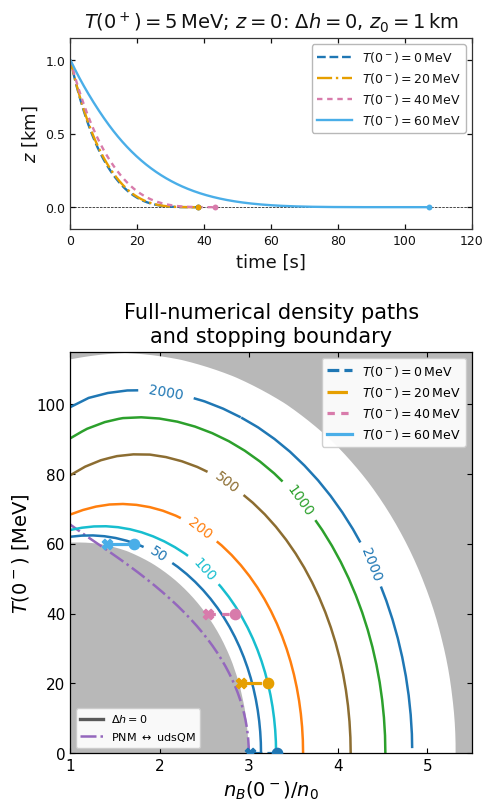

Saved /Users/janshao/NSM_related/local_analysis_results/26SU-12/paired-delta-h-zero-z0-100m.png


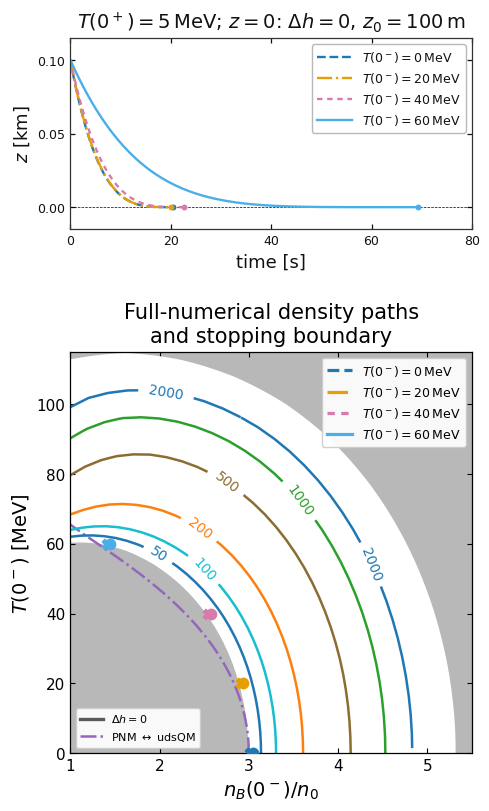

Saved /Users/janshao/NSM_related/local_analysis_results/26SU-12/paired-uds-equilibrium-z0-1km.png


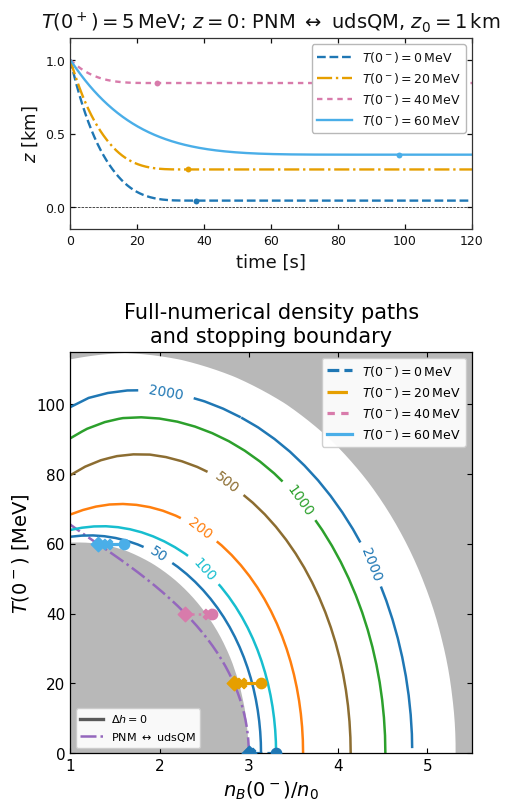

Saved /Users/janshao/NSM_related/local_analysis_results/26SU-12/paired-uds-equilibrium-z0-100m.png


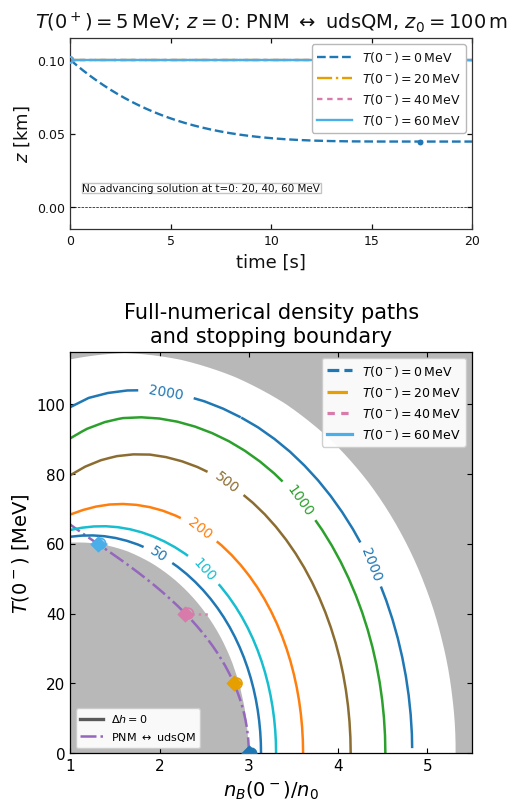

In [4]:
# Tunable plotting parameters
PAIRED_FIGURE_SIZE = (5.5, 8.0)
FIGURE_DPI = 100
EXPORT_DPI = 140
FIGURE_FACE_COLOR = "white"
AXES_FACE_COLOR = "white"
CONSTRAINED_LAYOUT = True
GRID_HEIGHT_RATIOS = (2.26, 4.74)
GRID_VERTICAL_SPACING = 0.08
TIME_BOX_ASPECT = 2.26 / 4.74
CONTOUR_BOX_ASPECT = 1.0
SERIES_COLORS = ("#1f77b4", "#e69f00", "#d87bab", "#4aaee8")
SERIES_LINE_STYLES = ("--", "-.", (0, (2.3, 2.0)), "-")
TIME_LINE_WIDTH = 1.7
TIME_MARKER_SIZE = 18
TIME_TITLE_FONT_SIZE = 14
TIME_AXIS_LABEL_FONT_SIZE = 13
TIME_TICK_LABEL_FONT_SIZE = 9
TIME_LEGEND_FONT_SIZE = 9
TIME_TITLE_PAD = 7.0
TIME_TICK_DIRECTION = "in"
TIME_TICK_LENGTH = 3.5
TIME_TICK_WIDTH = 0.9
TIME_SHOW_TOP_TICKS = True
TIME_SHOW_RIGHT_TICKS = True
TIME_SPINE_LINE_WIDTH = 0.9
TIME_SPINE_COLOR = "#333333"
TIME_TEXT_COLOR = "#111111"
TIME_LEGEND_LOCATION = "upper right"
TIME_LEGEND_FRAME_ON = True
TIME_LEGEND_FRAME_ALPHA = 1.0
TIME_LEGEND_FACE_COLOR = "white"
TIME_LEGEND_EDGE_COLOR = "#b8b8b8"
TIME_LEGEND_HANDLE_LENGTH = 2.8
ZERO_REFERENCE_LINE_COLOR = "black"
ZERO_REFERENCE_LINE_STYLE = "--"
ZERO_REFERENCE_LINE_WIDTH = 0.5
STOP_MARKER_STYLE = "o"
STOP_MARKER_EDGE_WIDTH = 0.0
STOP_MARKER_ZORDER = 7
NO_ADVANCING_MARKER_STYLE = "o"
NO_ADVANCING_MARKER_FACE_COLOR = "none"
NO_ADVANCING_MARKER_EDGE_WIDTH = 1.2
NO_ADVANCING_ANNOTATION_POSITION = (0.03, 0.20)
NO_ADVANCING_ANNOTATION_FONT_SIZE = 7.5
NO_ADVANCING_ANNOTATION_BOX_FACE_COLOR = "white"
NO_ADVANCING_ANNOTATION_BOX_EDGE_COLOR = "0.75"
NO_ADVANCING_ANNOTATION_BOX_ALPHA = 0.92
NO_ADVANCING_ANNOTATION_BOX_PAD = 0.2
TIME_Y_PADDING_FRACTION = 0.15
TIME_Y_TICKS_1KM = (0.0, 0.5, 1.0)
TIME_Y_TICKS_100M = (0.0, 0.05, 0.10)
CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4")
CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 10
CONTOUR_PATH_LINE_WIDTH = 2.3
UNREACHABLE_PATH_LINE_STYLE = ":"
UNREACHABLE_PATH_LINE_WIDTH = 1.8
UNREACHABLE_PATH_ALPHA = 0.9
CONTOUR_INITIAL_MARKER = "o"
CONTOUR_STOP_MARKER = "X"
CONTOUR_REFERENCE_MARKER = "D"
CONTOUR_MARKER_SIZE = 55
CONTOUR_NO_ADVANCING_MARKER_SIZE = 60
CONTOUR_MARKER_ZORDER = 7
BOUNDARY_INTERPOLATION_SAMPLES = 500
EXCLUDED_REGION_COLOR = "0.72"
BOUNDARY_COLOR = "white"
BOUNDARY_LINE_WIDTH = 2.4
UDS_TRANSITION_COLOR = "#9467bd"
UDS_TRANSITION_STYLE = "-."
UDS_TRANSITION_WIDTH = 1.8
CONTOUR_X_LIMITS = (1.0, 5.5)
CONTOUR_Y_LIMITS_MEV = (0.0, 115.0)
CONTOUR_TITLE_FONT_SIZE = 15
CONTOUR_TITLE_PAD = 7.0
CONTOUR_AXIS_LABEL_FONT_SIZE = 14
CONTOUR_TICK_LABEL_FONT_SIZE = 11
CONTOUR_TICK_DIRECTION = "in"
CONTOUR_SHOW_TOP_TICKS = True
CONTOUR_SHOW_RIGHT_TICKS = True
CONTOUR_SPINE_LINE_WIDTH = 0.9
CONTOUR_TEMPERATURE_LEGEND_LOCATION = "upper right"
CONTOUR_TEMPERATURE_LEGEND_FONT_SIZE = 9
CONTOUR_BOUNDARY_LEGEND_LOCATION = "lower left"
CONTOUR_BOUNDARY_LEGEND_FONT_SIZE = 8
LEGEND_FRAME_ALPHA = 0.92

theta_boundary = np.linspace(0.0, 0.5 * np.pi, BOUNDARY_INTERPOLATION_SAMPLES)
inner_density, inner_temperature = physical_state_from_native(theta_boundary, 0.0)
outer_density, outer_temperature = physical_state_from_native(theta_boundary, 1.0)
masked_velocity = np.ma.masked_where(
    ~success_grid | ~np.isfinite(velocity_grid_m_s), velocity_grid_m_s
)

temperature_handles = tuple(
    Line2D(
        (0.0,), (0.0,), color=color, linestyle=line_style,
        linewidth=CONTOUR_PATH_LINE_WIDTH,
        label=rf"$T(0^-)={temperature:g}\,\mathrm{{MeV}}$",
    )
    for temperature, color, line_style in zip(
        TEMPERATURES_0MINUS_MEV, SERIES_COLORS, SERIES_LINE_STYLES
    )
)
boundary_handles = (
    Line2D(
        (0.0,), (0.0,), color="0.35", linestyle="-",
        linewidth=BOUNDARY_LINE_WIDTH, label=r"$\Delta h=0$",
    ),
    Line2D(
        (0.0,), (0.0,), color=UDS_TRANSITION_COLOR,
        linestyle=UDS_TRANSITION_STYLE, linewidth=UDS_TRANSITION_WIDTH,
        label=r"PNM $\leftrightarrow$ udsQM",
    ),
)

for scenario in SCENARIO_RESULTS:
    figure, axes = plt.subplots(
        2,
        1,
        figsize=PAIRED_FIGURE_SIZE,
        dpi=FIGURE_DPI,
        facecolor=FIGURE_FACE_COLOR,
        constrained_layout=CONSTRAINED_LAYOUT,
        gridspec_kw={
            "height_ratios": GRID_HEIGHT_RATIOS,
            "hspace": GRID_VERTICAL_SPACING,
        },
    )
    axis_time, axis_contour = axes
    axis_time.set_facecolor(AXES_FACE_COLOR)
    axis_contour.set_facecolor(AXES_FACE_COLOR)
    axis_time.set_box_aspect(TIME_BOX_ASPECT)
    axis_contour.set_box_aspect(CONTOUR_BOX_ASPECT)

    axis_time.axhline(
        0.0,
        color=ZERO_REFERENCE_LINE_COLOR,
        linestyle=ZERO_REFERENCE_LINE_STYLE,
        linewidth=ZERO_REFERENCE_LINE_WIDTH,
    )
    no_advancing_temperatures = []
    for result, color, line_style in zip(
        scenario["results"], SERIES_COLORS, SERIES_LINE_STYLES
    ):
        if result["status"] == "no_advancing_solution":
            plot_time_s = np.linspace(
                0.0, scenario["time_window_s"], EVOLUTION_OUTPUT_COUNT
            )
            no_advancing_temperatures.append(result["temperature_0minus_MeV"])
        elif scenario["reference_kind"] == REFERENCE_UDS_EQUILIBRIUM:
            plot_time_s = np.linspace(
                0.0, scenario["time_window_s"], EVOLUTION_OUTPUT_COUNT
            )
        else:
            plot_time_s = np.linspace(
                0.0, result["stop_time_s"], EVOLUTION_OUTPUT_COUNT
            )
        plot_distance_km = result["distance_at_time"](plot_time_s)
        axis_time.plot(
            plot_time_s,
            plot_distance_km,
            color=color,
            linestyle=line_style,
            linewidth=TIME_LINE_WIDTH,
            label=rf"$T(0^-)={result['temperature_0minus_MeV']:g}\,\mathrm{{MeV}}$",
        )
        if result["status"] == "no_advancing_solution":
            axis_time.scatter(
                [0.0],
                [result["z0_km"]],
                facecolors=NO_ADVANCING_MARKER_FACE_COLOR,
                edgecolors=color,
                marker=NO_ADVANCING_MARKER_STYLE,
                s=TIME_MARKER_SIZE,
                linewidths=NO_ADVANCING_MARKER_EDGE_WIDTH,
                zorder=STOP_MARKER_ZORDER,
            )
        else:
            axis_time.scatter(
                [result["stop_time_s"]],
                [result["z_stall_km"]],
                color=color,
                marker=STOP_MARKER_STYLE,
                s=TIME_MARKER_SIZE,
                linewidths=STOP_MARKER_EDGE_WIDTH,
                zorder=STOP_MARKER_ZORDER,
            )

    if no_advancing_temperatures:
        temperature_text = ", ".join(
            f"{temperature:g}" for temperature in no_advancing_temperatures
        )
        axis_time.text(
            *NO_ADVANCING_ANNOTATION_POSITION,
            f"No advancing solution at t=0: {temperature_text} MeV",
            transform=axis_time.transAxes,
            fontsize=NO_ADVANCING_ANNOTATION_FONT_SIZE,
            color=TIME_TEXT_COLOR,
            bbox={
                "facecolor": NO_ADVANCING_ANNOTATION_BOX_FACE_COLOR,
                "edgecolor": NO_ADVANCING_ANNOTATION_BOX_EDGE_COLOR,
                "alpha": NO_ADVANCING_ANNOTATION_BOX_ALPHA,
                "pad": NO_ADVANCING_ANNOTATION_BOX_PAD,
            },
        )

    time_y_padding_km = TIME_Y_PADDING_FRACTION * scenario["z0_km"]
    axis_time.set_xlim(0.0, scenario["time_window_s"])
    axis_time.set_ylim(-time_y_padding_km, scenario["z0_km"] + time_y_padding_km)
    axis_time.set_xticks(
        np.arange(
            0.0,
            scenario["time_window_s"] + 0.5 * scenario["time_tick_step_s"],
            scenario["time_tick_step_s"],
        )
    )
    axis_time.set_yticks(
        TIME_Y_TICKS_1KM if np.isclose(scenario["z0_km"], 1.0) else TIME_Y_TICKS_100M
    )
    axis_time.set_title(
        rf"$T(0^+)=5\,\mathrm{{MeV}}$; {scenario['title']}",
        fontsize=TIME_TITLE_FONT_SIZE,
        color=TIME_TEXT_COLOR,
        pad=TIME_TITLE_PAD,
    )
    axis_time.set_xlabel("time [s]", fontsize=TIME_AXIS_LABEL_FONT_SIZE, color=TIME_TEXT_COLOR)
    axis_time.set_ylabel(r"$z$ [km]", fontsize=TIME_AXIS_LABEL_FONT_SIZE, color=TIME_TEXT_COLOR)
    axis_time.tick_params(
        axis="both", which="both", direction=TIME_TICK_DIRECTION,
        top=TIME_SHOW_TOP_TICKS, right=TIME_SHOW_RIGHT_TICKS,
        length=TIME_TICK_LENGTH, width=TIME_TICK_WIDTH,
        labelsize=TIME_TICK_LABEL_FONT_SIZE, colors=TIME_TEXT_COLOR,
    )
    for spine in axis_time.spines.values():
        spine.set_linewidth(TIME_SPINE_LINE_WIDTH)
        spine.set_color(TIME_SPINE_COLOR)
    time_legend = axis_time.legend(
        loc=TIME_LEGEND_LOCATION,
        fontsize=TIME_LEGEND_FONT_SIZE,
        frameon=TIME_LEGEND_FRAME_ON,
        framealpha=TIME_LEGEND_FRAME_ALPHA,
        facecolor=TIME_LEGEND_FACE_COLOR,
        edgecolor=TIME_LEGEND_EDGE_COLOR,
        handlelength=TIME_LEGEND_HANDLE_LENGTH,
    )
    for legend_text in time_legend.get_texts():
        legend_text.set_color(TIME_TEXT_COLOR)

    inner_polygon_x = np.concatenate((inner_density, (CONTOUR_X_LIMITS[0], inner_density[0])))
    inner_polygon_y = np.concatenate((inner_temperature, (CONTOUR_Y_LIMITS_MEV[0], CONTOUR_Y_LIMITS_MEV[0])))
    axis_contour.fill(inner_polygon_x, inner_polygon_y, color=EXCLUDED_REGION_COLOR)
    outer_polygon_x = np.concatenate(
        (outer_density, (CONTOUR_X_LIMITS[0], CONTOUR_X_LIMITS[1], CONTOUR_X_LIMITS[1], outer_density[0]))
    )
    outer_polygon_y = np.concatenate(
        (outer_temperature, (CONTOUR_Y_LIMITS_MEV[1], CONTOUR_Y_LIMITS_MEV[1], CONTOUR_Y_LIMITS_MEV[0], CONTOUR_Y_LIMITS_MEV[0]))
    )
    axis_contour.fill(outer_polygon_x, outer_polygon_y, color=EXCLUDED_REGION_COLOR)
    axis_contour.plot(
        inner_density, inner_temperature,
        color=BOUNDARY_COLOR, linewidth=BOUNDARY_LINE_WIDTH,
    )
    axis_contour.plot(
        outer_density, outer_temperature,
        color=BOUNDARY_COLOR, linewidth=BOUNDARY_LINE_WIDTH,
    )
    axis_contour.plot(
        uds_equilibrium_density_over_n0,
        uds_equilibrium_temperature_MeV,
        color=UDS_TRANSITION_COLOR,
        linestyle=UDS_TRANSITION_STYLE,
        linewidth=UDS_TRANSITION_WIDTH,
    )
    numerical_contours = axis_contour.contour(
        density_grid,
        temperature_0minus_grid,
        masked_velocity,
        levels=CONTOUR_LEVELS_M_S,
        colors=CONTOUR_COLORS,
        linewidths=CONTOUR_LINE_WIDTH,
    )
    axis_contour.clabel(
        numerical_contours,
        inline=True,
        fmt="%g",
        fontsize=CONTOUR_LABEL_FONT_SIZE,
    )

    for result, color, line_style in zip(
        scenario["results"], SERIES_COLORS, SERIES_LINE_STYLES
    ):
        temperature_value = result["temperature_0minus_MeV"]
        if result["status"] != "no_advancing_solution":
            traversed_density = np.linspace(
                result["delta_h_zero_density_over_n0"],
                result["initial_density_over_n0"],
                150,
            )
            axis_contour.plot(
                traversed_density,
                np.full_like(traversed_density, temperature_value),
                color=color,
                linestyle=line_style,
                linewidth=CONTOUR_PATH_LINE_WIDTH,
            )
        if scenario["reference_kind"] == REFERENCE_UDS_EQUILIBRIUM:
            unreachable_density = np.linspace(
                result["reference_density_over_n0"],
                result["delta_h_zero_density_over_n0"],
                150,
            )
            axis_contour.plot(
                unreachable_density,
                np.full_like(unreachable_density, temperature_value),
                color=color,
                linestyle=UNREACHABLE_PATH_LINE_STYLE,
                linewidth=UNREACHABLE_PATH_LINE_WIDTH,
                alpha=UNREACHABLE_PATH_ALPHA,
            )
            axis_contour.scatter(
                result["reference_density_over_n0"],
                temperature_value,
                color=color,
                marker=CONTOUR_REFERENCE_MARKER,
                s=CONTOUR_MARKER_SIZE,
                zorder=CONTOUR_MARKER_ZORDER,
            )
        if result["status"] == "no_advancing_solution":
            axis_contour.scatter(
                result["initial_density_over_n0"],
                temperature_value,
                facecolors=NO_ADVANCING_MARKER_FACE_COLOR,
                edgecolors=color,
                marker=CONTOUR_INITIAL_MARKER,
                s=CONTOUR_NO_ADVANCING_MARKER_SIZE,
                linewidths=NO_ADVANCING_MARKER_EDGE_WIDTH,
                zorder=CONTOUR_MARKER_ZORDER,
            )
        else:
            axis_contour.scatter(
                result["initial_density_over_n0"],
                temperature_value,
                color=color,
                marker=CONTOUR_INITIAL_MARKER,
                s=CONTOUR_MARKER_SIZE,
                zorder=CONTOUR_MARKER_ZORDER,
            )
            axis_contour.scatter(
                result["delta_h_zero_density_over_n0"],
                temperature_value,
                color=color,
                marker=CONTOUR_STOP_MARKER,
                s=CONTOUR_MARKER_SIZE,
                zorder=CONTOUR_MARKER_ZORDER,
            )

    axis_contour.set_xlim(*CONTOUR_X_LIMITS)
    axis_contour.set_ylim(*CONTOUR_Y_LIMITS_MEV)
    axis_contour.set_xlabel(r"$n_B(0^-)/n_0$", fontsize=CONTOUR_AXIS_LABEL_FONT_SIZE)
    axis_contour.set_ylabel(r"$T(0^-)$ [MeV]", fontsize=CONTOUR_AXIS_LABEL_FONT_SIZE)
    axis_contour.set_title(
        "Full-numerical density paths\nand stopping boundary",
        fontsize=CONTOUR_TITLE_FONT_SIZE,
        pad=CONTOUR_TITLE_PAD,
    )
    axis_contour.tick_params(
        direction=CONTOUR_TICK_DIRECTION,
        top=CONTOUR_SHOW_TOP_TICKS,
        right=CONTOUR_SHOW_RIGHT_TICKS,
        labelsize=CONTOUR_TICK_LABEL_FONT_SIZE,
    )
    for spine in axis_contour.spines.values():
        spine.set_linewidth(CONTOUR_SPINE_LINE_WIDTH)
    temperature_legend = axis_contour.legend(
        handles=temperature_handles,
        loc=CONTOUR_TEMPERATURE_LEGEND_LOCATION,
        fontsize=CONTOUR_TEMPERATURE_LEGEND_FONT_SIZE,
        framealpha=LEGEND_FRAME_ALPHA,
    )
    axis_contour.add_artist(temperature_legend)
    axis_contour.legend(
        handles=boundary_handles,
        loc=CONTOUR_BOUNDARY_LEGEND_LOCATION,
        fontsize=CONTOUR_BOUNDARY_LEGEND_FONT_SIZE,
        framealpha=LEGEND_FRAME_ALPHA,
    )

    output_png = OUTPUT_DIRECTORY / f"{scenario['output_stem']}.png"
    output_pdf = OUTPUT_DIRECTORY / f"{scenario['output_stem']}.pdf"
    figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=FIGURE_FACE_COLOR)
    figure.savefig(output_pdf, dpi=EXPORT_DPI, facecolor=FIGURE_FACE_COLOR)
    print(f"Saved {output_png}")
    plt.show()